# Decision Trees and	Random	Forests: Predicting Academic Success

In this analysis, we aim to move beyond simple grades and understand the behaviors that separate top students from the rest of the cohort. Instead of using an arbitrary cutoff, we define a "High Performer" as any student scoring above the median Exam Score (67%). This ensures a balanced dataset for our machine learning algorithms.


* **Project Objective**
Our task is to create a robust model that accurately predicts these High Performers based on a variety of features. We will begin by implementing a Decision Tree to visualize the logic of student success, and then we will refine our results using a Random Forest Ensemble to ensure maximum accuracy and stability.

* **The Dataset**
We will use the Student Performance Factors dataset from Kaggle [Student Exam Performance Dataset Analysis](https://www.kaggle.com/datasets/grandmaster07/student-exam-performance-dataset-analysis/data). This dataset consists of 6,607 student records and contains 20 unique features covering academic, behavioral, and socio-economic factors.

* **Methodology**
    We will implement the following data science workflow:

    * Exploratory Data Analysis (EDA): Visualizing key trends to understand the raw data.

    * Decision Tree Modeling: Building an interpretable "Logic Tree" to see how decisions are made.

    * Model Optimization: Using K-Fold Cross-Validation and Overfitting Analysis to find the optimal tree depth.

    * Feature Importance: Identifying the most significant predictors of academic achievement.

    * Random Forest Ensemble: Implementing a robust ensemble of 100 trees to achieve maximum predictive accuracy.



First we need to import neccesary libraries and load the dataset into our notebook.

In [26]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn import tree
from sklearn import metrics

# Load the training dataset
student_df = pd.read_csv("data/StudentPerformanceFactors.csv")

student_df.head()

,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
0,23,84,Low,High,No,7,73,Low,Yes,0,Low,Medium,Public,Positive,3,No,High School,Near,Male,67
1,19,64,Low,Medium,No,8,59,Low,Yes,2,Medium,Medium,Public,Negative,4,No,College,Moderate,Female,61
2,24,98,Medium,Medium,Yes,7,91,Medium,Yes,2,Medium,Medium,Public,Neutral,4,No,Postgraduate,Near,Male,74
3,29,89,Low,Medium,Yes,8,98,Medium,Yes,1,Medium,Medium,Public,Negative,4,No,High School,Moderate,Male,71
4,19,92,Medium,Medium,Yes,6,65,Medium,Yes,3,Medium,High,Public,Neutral,4,No,College,Near,Female,70


Calculate the median Exam_Score to define our performance threshold.

In [27]:
# Calculate the median Exam_Score 
median_score = student_df['Exam_Score'].median()
print('The median Exam Score is:', median_score)

The median Exam Score is: 67.0


We will convert the continuous Exam_Score into a binary target variable named Is_High_Performer. This allows us to use a Decision Tree Model to predict student success categories.

In [28]:
# We define "High Performer" (1) as any student scoring ABOVE the median
student_df['Is_High_Performer'] = np.where(student_df['Exam_Score'] > median_score, 1, 0)

# Print out information about the dataframe
student_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6607 entries, 0 to 6606
Data columns (total 21 columns):
 #   Column                      Non-Null Count  Dtype 
---  ------                      --------------  ----- 
 0   Hours_Studied               6607 non-null   int64 
 1   Attendance                  6607 non-null   int64 
 2   Parental_Involvement        6607 non-null   object
 3   Access_to_Resources         6607 non-null   object
 4   Extracurricular_Activities  6607 non-null   object
 5   Sleep_Hours                 6607 non-null   int64 
 6   Previous_Scores             6607 non-null   int64 
 7   Motivation_Level            6607 non-null   object
 8   Internet_Access             6607 non-null   object
 9   Tutoring_Sessions           6607 non-null   int64 
 10  Family_Income               6607 non-null   object
 11  Teacher_Quality             6529 non-null   object
 12  School_Type                 6607 non-null   object
 13  Peer_Influence              6607 non-null   obje

The dataset contains 6607 observations (i.e. students), 20 features and the target variable is Exam Score which we transform to new features (Is_High_Performer).

Let's calculate the probability of being a High Performer (scoring above the median) without using any feature information:

In [29]:
# Calculate baseline probability (How many students are High Performers?)
high_perf_prob = sum(student_df.Is_High_Performer) / len(student_df)
print('Probability of a student being a High Performer is:', np.round(high_perf_prob, 2))

Probability of a student being a High Performer is: 0.46


In [30]:
print(round(1-high_perf_prob,2))

0.54


This is the Probability of a student being a Non High Performer it also the accuracy we need to beat!

In [31]:
# Look at the first 10 rows of the dataframe
student_df.head(10)

,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,...,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score,Is_High_Performer
0,23,84,Low,High,No,7,73,Low,Yes,0,...,Medium,Public,Positive,3,No,High School,Near,Male,67,0
1,19,64,Low,Medium,No,8,59,Low,Yes,2,...,Medium,Public,Negative,4,No,College,Moderate,Female,61,0
2,24,98,Medium,Medium,Yes,7,91,Medium,Yes,2,...,Medium,Public,Neutral,4,No,Postgraduate,Near,Male,74,1
3,29,89,Low,Medium,Yes,8,98,Medium,Yes,1,...,Medium,Public,Negative,4,No,High School,Moderate,Male,71,1
4,19,92,Medium,Medium,Yes,6,65,Medium,Yes,3,...,High,Public,Neutral,4,No,College,Near,Female,70,1
5,19,88,Medium,Medium,Yes,8,89,Medium,Yes,3,...,Medium,Public,Positive,3,No,Postgraduate,Near,Male,71,1
6,29,84,Medium,Low,Yes,7,68,Low,Yes,1,...,Medium,Private,Neutral,2,No,High School,Moderate,Male,67,0
7,25,78,Low,High,Yes,6,50,Medium,Yes,1,...,High,Public,Negative,2,No,High School,Far,Male,66,0
8,17,94,Medium,High,No,6,80,High,Yes,0,...,Low,Private,Neutral,1,No,College,Near,Male,69,1
9,23,98,Medium,Medium,Yes,8,71,Medium,Yes,0,...,High,Public,Positive,5,No,High School,Moderate,Male,72,1


The dataframe is displayed in a tidy format with observations in rows and with features and the target variable in columns. The features are as follows:

* **Hours_Studied**: Weekly study hours.
* **Attendance**: Percentage of classes attended.
* **Parental_Involvement**: Level of parental support ('Low', 'Medium', or 'High').
* **Access_to_Resources**: Access to educational tools ('Low', 'Medium', or 'High').
* **Extracurricular_Activities**: Participation in non-academic activities ('Yes' or 'No').
* **Sleep_Hours**: Average hours of sleep per night.
* **Previous_Scores**: Scores from previous academic assessments.
* **Motivation_Level**: Student's drive to succeed ('Low', 'Medium', or 'High').
* **Internet_Access**: Availability of internet at home ('Yes' or 'No').
* **Tutoring_Sessions**: Number of extra tutoring sessions attended.
* **Family_Income**: Socio-economic status indicator ('Low', 'Medium', or 'High').
* **Teacher_Quality**: Rating of instructor effectiveness ('Low', 'Medium', or 'High').
* **School_Type**: Type of institution ('Public' or 'Private').
* **Peer_Influence**: Impact of friends ('Positive', 'Neutral', or 'Negative').
* **Physical_Activity**: Hours of exercise per week.
* **Learning_Disabilities**: Presence of any learning challenges ('Yes' or 'No').
* **Parental_Education_Level**: Highest degree held by parents.
* **Distance_from_Home**: Commute distance ('Near', 'Moderate', or 'Far').
* **Gender**: Student gender ('Male' or 'Female').
* **Exam_Score**: Final test result (Original continuous target).
* **Is_High_Performer**: Performance status ($0=$ 'Low Performer', $1=$ 'High Performer').

We can print unique categories for all categorical features as below:

In [6]:
# --- Print unique categories for all categorical features ---
print('Parental_Involvement categories are:', student_df.Parental_Involvement.unique())
print('Access_to_Resources categories are:', student_df.Access_to_Resources.unique())
print('Extracurricular_Activities categories are:', student_df.Extracurricular_Activities.unique())
print('Motivation_Level categories are:', student_df.Motivation_Level.unique())
print('Internet_Access categories are:', student_df.Internet_Access.unique())
print('Family_Income categories are:', student_df.Family_Income.unique())
print('Teacher_Quality categories are:', student_df.Teacher_Quality.unique())
print('School_Type categories are:', student_df.School_Type.unique())
print('Peer_Influence categories are:', student_df.Peer_Influence.unique())
print('Learning_Disabilities categories are:', student_df.Learning_Disabilities.unique())
print('Parental_Education_Level categories are:', student_df.Parental_Education_Level.unique())
print('Distance_from_Home categories are:', student_df.Distance_from_Home.unique())
print('Gender categories are:', student_df.Gender.unique())

Parental_Involvement categories are: ['Low' 'Medium' 'High']
Access_to_Resources categories are: ['High' 'Medium' 'Low']
Extracurricular_Activities categories are: ['No' 'Yes']
Motivation_Level categories are: ['Low' 'Medium' 'High']
Internet_Access categories are: ['Yes' 'No']
Family_Income categories are: ['Low' 'Medium' 'High']
Teacher_Quality categories are: ['Medium' 'High' 'Low' nan]
School_Type categories are: ['Public' 'Private']
Peer_Influence categories are: ['Positive' 'Negative' 'Neutral']
Learning_Disabilities categories are: ['No' 'Yes']
Parental_Education_Level categories are: ['High School' 'College' 'Postgraduate' nan]
Distance_from_Home categories are: ['Near' 'Moderate' 'Far' nan]
Gender categories are: ['Male' 'Female']


# Exploratory Data Analysis (EDA) 


Let's start by looking at the effect of student effort. 

We can plot histograms of the distributions for 'Hours_Studied' and 'Attendance' for the two target classes 'High Performer' and 'Low Performer':

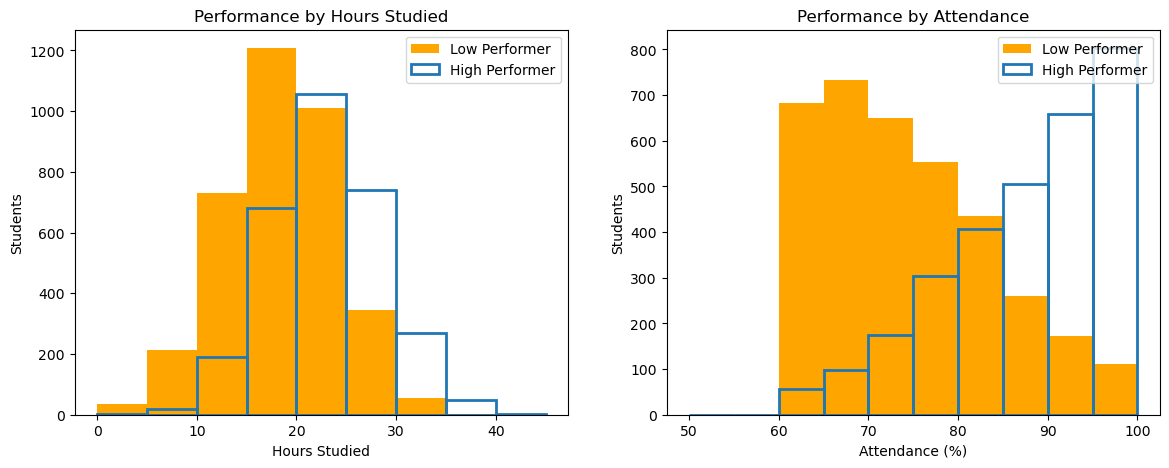

In [7]:
import matplotlib.pyplot as plt

# Set up the figure with two subplots side-by-side
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# --- 1. Hours Studied ---
# Define bins for study hours (e.g., 0 to 45 in steps of 5)
bins_hours = [0, 5, 10, 15, 20, 25, 30, 35, 40, 45]

ax1.hist(student_df.loc[student_df['Is_High_Performer']==0].Hours_Studied, bins=bins_hours, color='orange', label='Low Performer')
ax1.hist(student_df.loc[student_df['Is_High_Performer']==1].Hours_Studied, bins=bins_hours, facecolor='none', edgecolor='tab:blue', linewidth=2, label='High Performer')
ax1.set_xlabel('Hours Studied')
ax1.set_ylabel('Students')
ax1.set_title('Performance by Hours Studied')
ax1.legend()

# --- 2. Attendance ---
# Define bins for attendance (e.g., 50 to 100 in steps of 5)
bins_attendance = [50, 55, 60, 65, 70, 75, 80, 85, 90, 95, 100]

ax2.hist(student_df.loc[student_df['Is_High_Performer']==0].Attendance, bins=bins_attendance, color='orange', label='Low Performer')
ax2.hist(student_df.loc[student_df['Is_High_Performer']==1].Attendance, bins=bins_attendance, facecolor='none', edgecolor='tab:blue', linewidth=2, label='High Performer')
ax2.set_xlabel('Attendance (%)')
ax2.set_ylabel('Students')
ax2.set_title('Performance by Attendance')
ax2.legend()

plt.savefig('EDA1.png', bbox_inches='tight', dpi=300)
plt.show()

Based on the histograms we created:

* Hours Studied: Students who dedicate 15-20 hours per week for studying are significantly more likely to be High Performers.**

* Attendance Percentage: This feature shows a drastic separation between the two groups. High Performers are heavily clustered at the top end of the scale, with a massive spike between 90% and 100% attendance. Conversely, it is extremely rare for a student with less than 75% attendance to achieve High Performer stat** 

Next, we will look into the other support systems students receive by examining Parental Involvement and Tutoring Sessions:

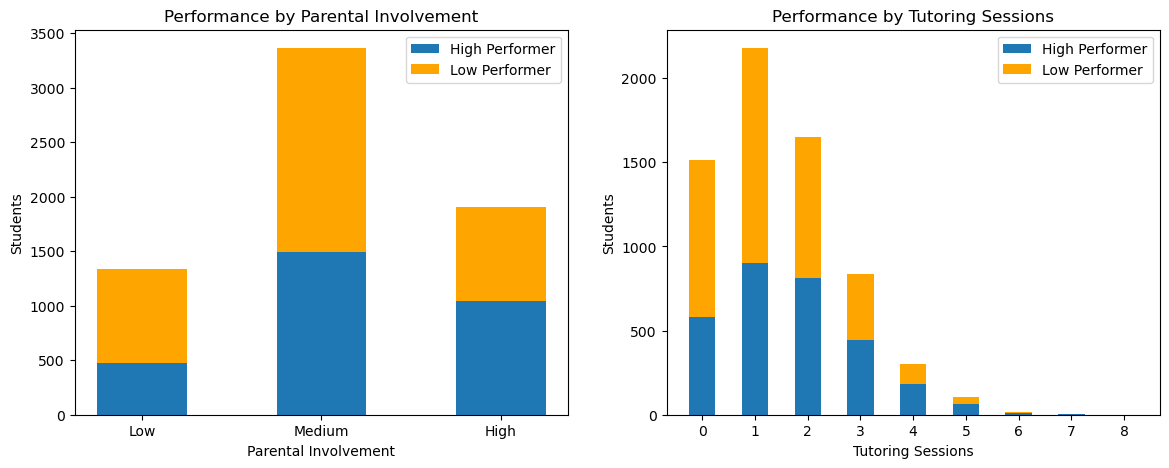

In [8]:
import matplotlib.pyplot as plt

# Set up the figure with two subplots side-by-side
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
width = 0.5

# Parental Involvement 
categories_pi = ['Low', 'Medium', 'High']
pi_high = []
pi_low = []

for cat in categories_pi:
    # Calculate number of High Performers and Low Performers
    tmp_high = sum(student_df.loc[student_df['Parental_Involvement']==cat].Is_High_Performer)
    pi_high.append(tmp_high)
    
    tmp_low = len(student_df.loc[student_df['Parental_Involvement']==cat].Is_High_Performer) - tmp_high
    pi_low.append(tmp_low)

ax1.bar(categories_pi, pi_high, width, label='High Performer', color='tab:blue')
ax1.bar(categories_pi, pi_low, width, bottom=pi_high, label='Low Performer', color='orange')
ax1.set_xlabel('Parental Involvement')
ax1.set_ylabel('Students')
ax1.set_title('Performance by Parental Involvement')
ax1.legend()


#Tutoring Sessions
unique_tutoring = sorted(student_df.Tutoring_Sessions.unique()) # Sorts into ascending order
tutoring_high = [] 
tutoring_low = [] 

for sessions in unique_tutoring:
    tmp_high = sum(student_df.loc[student_df['Tutoring_Sessions']==sessions].Is_High_Performer)
    tutoring_high.append(tmp_high)
    
    tmp_low = len(student_df.loc[student_df['Tutoring_Sessions']==sessions].Is_High_Performer) - tmp_high
    tutoring_low.append(tmp_low)

# Convert each value to a string for plot labels
labels_tutoring = [str(x) for x in unique_tutoring] 

ax2.bar(labels_tutoring, tutoring_high, width, label='High Performer', color='tab:blue')
ax2.bar(labels_tutoring, tutoring_low, width, bottom=tutoring_high, label='Low Performer', color='orange')
ax2.set_xlabel('Tutoring Sessions')
ax2.set_ylabel('Students')
ax2.set_title('Performance by Tutoring Sessions')
ax2.legend()

plt.savefig('EDA2.png', bbox_inches='tight', dpi=300)

plt.show()

In [9]:
# --- Proportions by Parental Involvement ---
print("--- Parental Involvement Proportions ---")
categories_pi = ['Low', 'Medium', 'High']

for cat in categories_pi:
    subset = student_df.loc[student_df['Parental_Involvement'] == cat]
    high_count = sum(subset['Is_High_Performer'])
    total_count = len(subset)
    
    # Calculate percentage
    percentage = round((high_count * 100) / total_count, 1)
    print(f'High Performance rate for {cat} Involvement:', percentage, '%')

print("\n--- Tutoring Sessions Proportions ---")
# --- Proportions by Tutoring Sessions ---
unique_tutoring = sorted(student_df.Tutoring_Sessions.unique())

for session in unique_tutoring:
    subset = student_df.loc[student_df['Tutoring_Sessions'] == session]
    high_count = sum(subset['Is_High_Performer'])
    total_count = len(subset)
    
    # Calculate percentage 
    if total_count > 0: # Prevents dividing by zero
        percentage = round((high_count * 100) / total_count, 1)
        print(f'High Performance rate with {session} Tutoring Sessions:', percentage, '%')

--- Parental Involvement Proportions ---
High Performance rate for Low Involvement: 35.3 %
High Performance rate for Medium Involvement: 44.3 %
High Performance rate for High Involvement: 54.8 %

--- Tutoring Sessions Proportions ---
High Performance rate with 0 Tutoring Sessions: 38.5 %
High Performance rate with 1 Tutoring Sessions: 41.3 %
High Performance rate with 2 Tutoring Sessions: 49.4 %
High Performance rate with 3 Tutoring Sessions: 53.1 %
High Performance rate with 4 Tutoring Sessions: 60.5 %
High Performance rate with 5 Tutoring Sessions: 64.1 %
High Performance rate with 6 Tutoring Sessions: 72.2 %
High Performance rate with 7 Tutoring Sessions: 71.4 %
High Performance rate with 8 Tutoring Sessions: 100.0 %


Based on the charts and proportions calculated, we can see that more Parental Involvement and more Tutoring Sessions have a direct, positive impact on student performance, making them much likely to be High Performers.

Finally, we can look at the effect of socio-economic status by plotting the performance distributions for 'Family_Income' and 'Internet_Access'

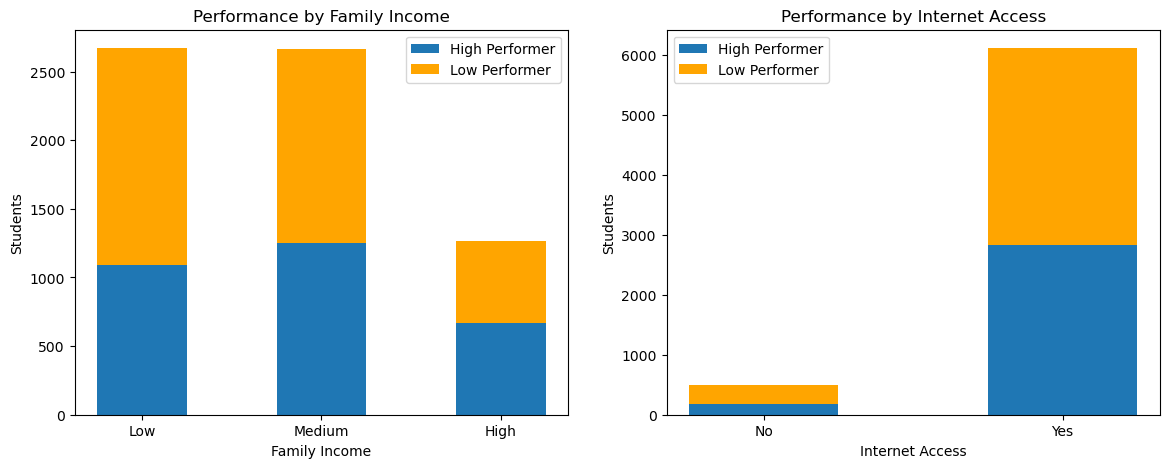

--- Family Income Proportions ---
High Performance rate for Low Income: 40.8 %
High Performance rate for Medium Income: 46.9 %
High Performance rate for High Income: 52.6 %

--- Internet Access Proportions ---
High Performance rate with Internet Access (No): 36.9 %
High Performance rate with Internet Access (Yes): 46.2 %


In [32]:
import matplotlib.pyplot as plt

# Set up the figure with two subplots side-by-side
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
width = 0.5

# Family Income 
categories_income = ['Low', 'Medium', 'High']
income_high = []
income_low = []

for cat in categories_income:
    # Calculate number of High Performers and Low Performers
    tmp_high = sum(student_df.loc[student_df['Family_Income']==cat].Is_High_Performer)
    income_high.append(tmp_high)
    
    tmp_low = len(student_df.loc[student_df['Family_Income']==cat].Is_High_Performer) - tmp_high
    income_low.append(tmp_low)

ax1.bar(categories_income, income_high, width, label='High Performer', color='tab:blue')
ax1.bar(categories_income, income_low, width, bottom=income_high, label='Low Performer', color='orange')
ax1.set_xlabel('Family Income')
ax1.set_ylabel('Students')
ax1.set_title('Performance by Family Income')
ax1.legend()


# Internet Access
categories_internet = ['No', 'Yes'] 
internet_high = [] 
internet_low = [] 

for cat in categories_internet:
    tmp_high = sum(student_df.loc[student_df['Internet_Access']==cat].Is_High_Performer)
    internet_high.append(tmp_high)
    
    tmp_low = len(student_df.loc[student_df['Internet_Access']==cat].Is_High_Performer) - tmp_high
    internet_low.append(tmp_low)

ax2.bar(categories_internet, internet_high, width, label='High Performer', color='tab:blue')
ax2.bar(categories_internet, internet_low, width, bottom=internet_high, label='Low Performer', color='orange')
ax2.set_xlabel('Internet Access')
ax2.set_ylabel('Students')
ax2.set_title('Performance by Internet Access')
ax2.legend()

plt.savefig('EDA3.png', bbox_inches='tight', dpi=300)

plt.show()

#  Proportions Output
print("--- Family Income Proportions ---")
for cat in categories_income:
    subset = student_df.loc[student_df['Family_Income'] == cat]
    high_count = sum(subset['Is_High_Performer'])
    total_count = len(subset)
    
    # Calculate percentage
    percentage = round((high_count * 100) / total_count, 1)
    print(f'High Performance rate for {cat} Income:', percentage, '%')

print("\n--- Internet Access Proportions ---")
for cat in categories_internet:
    subset = student_df.loc[student_df['Internet_Access'] == cat]
    high_count = sum(subset['Is_High_Performer'])
    total_count = len(subset)
    
    # Calculate percentage
    percentage = round((high_count * 100) / total_count, 1)
    print(f'High Performance rate with Internet Access ({cat}):', percentage, '%')

Based on the charts and proportions calculated, background metrics have a minimal impact. These small variances pale in comparison to the massive performance shifts driven by internal effort such as Attendacne and study hours.

# Cleaning the data

Before running our data through our machine learning algorithm we must clean it: we need to decide what to do with missing data (i.e. NaNs) and convert categorical variables to numbers. 

Let's start by looking at where we have NaNs in the dataframe:

In [11]:
import pandas as pd

# Go through each input feature checking if there are any (and how many) NaNs 
Features = student_df.columns.tolist() # Make a list of the feature names
print(Features)

for feature in Features:
    num = 0
    for i in range(0, len(student_df)):
        if pd.isnull(student_df.iloc[i][feature]) == True:
            num = num + 1
    print('NaNs for', feature ,'is', num)

['Hours_Studied', 'Attendance', 'Parental_Involvement', 'Access_to_Resources', 'Extracurricular_Activities', 'Sleep_Hours', 'Previous_Scores', 'Motivation_Level', 'Internet_Access', 'Tutoring_Sessions', 'Family_Income', 'Teacher_Quality', 'School_Type', 'Peer_Influence', 'Physical_Activity', 'Learning_Disabilities', 'Parental_Education_Level', 'Distance_from_Home', 'Gender', 'Exam_Score', 'Is_High_Performer']
NaNs for Hours_Studied is 0
NaNs for Attendance is 0
NaNs for Parental_Involvement is 0
NaNs for Access_to_Resources is 0
NaNs for Extracurricular_Activities is 0
NaNs for Sleep_Hours is 0
NaNs for Previous_Scores is 0
NaNs for Motivation_Level is 0
NaNs for Internet_Access is 0
NaNs for Tutoring_Sessions is 0
NaNs for Family_Income is 0
NaNs for Teacher_Quality is 78
NaNs for School_Type is 0
NaNs for Peer_Influence is 0
NaNs for Physical_Activity is 0
NaNs for Learning_Disabilities is 0
NaNs for Parental_Education_Level is 90
NaNs for Distance_from_Home is 67
NaNs for Gender is 

We identified missing values in 'Teacher_Quality', 'Parental_Education_Level', and 'Distance_from_Home'. Because these are categorical features, we will fill the missing (NaN) values with the mode (the most frequent category) for each respective column.

In [33]:
# Fill missing values with the mode 
# The [0] at the end just grabs the first word if there happens to be a tie for the most common answer
student_df['Teacher_Quality'] = student_df['Teacher_Quality'].fillna(student_df['Teacher_Quality'].mode()[0])
student_df['Parental_Education_Level'] = student_df['Parental_Education_Level'].fillna(student_df['Parental_Education_Level'].mode()[0])
student_df['Distance_from_Home'] = student_df['Distance_from_Home'].fillna(student_df['Distance_from_Home'].mode()[0])

# Check if there still NaNs in our dataset.
print("--- Missing values AFTER cleaning ---")
for feature in Features:
    num = 0
    for i in range(0, len(student_df)):
        if pd.isnull(student_df.iloc[i][feature]) == True:
            num = num + 1
    
    # Only print if there are still missing values (should print nothing!)
    if num > 0:
        print('NaNs for', feature ,'is', num)

print("Check complete. All NaNs handled!")

--- Missing values AFTER cleaning ---
Check complete. All NaNs handled!


Next, we will identify which features are categorical and encode them into numerical formats to prepare the dataset for modeling.

In [13]:
student_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6607 entries, 0 to 6606
Data columns (total 21 columns):
 #   Column                      Non-Null Count  Dtype 
---  ------                      --------------  ----- 
 0   Hours_Studied               6607 non-null   int64 
 1   Attendance                  6607 non-null   int64 
 2   Parental_Involvement        6607 non-null   object
 3   Access_to_Resources         6607 non-null   object
 4   Extracurricular_Activities  6607 non-null   object
 5   Sleep_Hours                 6607 non-null   int64 
 6   Previous_Scores             6607 non-null   int64 
 7   Motivation_Level            6607 non-null   object
 8   Internet_Access             6607 non-null   object
 9   Tutoring_Sessions           6607 non-null   int64 
 10  Family_Income               6607 non-null   object
 11  Teacher_Quality             6607 non-null   object
 12  School_Type                 6607 non-null   object
 13  Peer_Influence              6607 non-null   obje

In [34]:
#Map Binary Variables (Yes/No, Male/Female, Public/Private) to 0 and 1 
student_df['Gender'] = student_df['Gender'].map({'Male': 0, 'Female': 1})
student_df['Internet_Access'] = student_df['Internet_Access'].map({'No': 0, 'Yes': 1})
student_df['Extracurricular_Activities'] = student_df['Extracurricular_Activities'].map({'No': 0, 'Yes': 1})
student_df['Learning_Disabilities'] = student_df['Learning_Disabilities'].map({'No': 0, 'Yes': 1})
student_df['School_Type'] = student_df['School_Type'].map({'Public': 0, 'Private': 1})

#Map Ordinal Variables (Low/Medium/High) to 0, 1, and 2 
ordinal_mapping = {'Low': 0, 'Medium': 1, 'High': 2}
student_df['Parental_Involvement'] = student_df['Parental_Involvement'].map(ordinal_mapping)
student_df['Access_to_Resources'] = student_df['Access_to_Resources'].map(ordinal_mapping)
student_df['Motivation_Level'] = student_df['Motivation_Level'].map(ordinal_mapping)
student_df['Family_Income'] = student_df['Family_Income'].map(ordinal_mapping)
student_df['Teacher_Quality'] = student_df['Teacher_Quality'].map(ordinal_mapping)

#Map Custom Ordinal Variables
student_df['Distance_from_Home'] = student_df['Distance_from_Home'].map({'Near': 0, 'Moderate': 1, 'Far': 2})
student_df['Peer_Influence'] = student_df['Peer_Influence'].map({'Negative': 0, 'Neutral': 1, 'Positive': 2})
student_df['Parental_Education_Level'] = student_df['Parental_Education_Level'].map({'High School': 0, 'College': 1, 'Postgraduate': 2})

# Check data type for every features after converting
student_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6607 entries, 0 to 6606
Data columns (total 21 columns):
 #   Column                      Non-Null Count  Dtype
---  ------                      --------------  -----
 0   Hours_Studied               6607 non-null   int64
 1   Attendance                  6607 non-null   int64
 2   Parental_Involvement        6607 non-null   int64
 3   Access_to_Resources         6607 non-null   int64
 4   Extracurricular_Activities  6607 non-null   int64
 5   Sleep_Hours                 6607 non-null   int64
 6   Previous_Scores             6607 non-null   int64
 7   Motivation_Level            6607 non-null   int64
 8   Internet_Access             6607 non-null   int64
 9   Tutoring_Sessions           6607 non-null   int64
 10  Family_Income               6607 non-null   int64
 11  Teacher_Quality             6607 non-null   int64
 12  School_Type                 6607 non-null   int64
 13  Peer_Influence              6607 non-null   int64
 14  Physical

# Decision Tree Model

* **What is it?**
A Decision Tree is a machine learning model that works like a flowchart. It asks a series of "Yes/No" questions to sort students and predict if they will be a High Performer.

* **Why are we using it?**
We chose a Decision Tree for this initial model because student performance often hinges on specific thresholds rather than smooth linear trends, and this algorithm excels at mathematically locating those exact "tipping points." Furthermore, by using this model, the results will be easy to understand. A Decision Tree is highly interpretable, generating clear "If/Then" rules that educators can actually use to intervene and support a student.

First, we split the dataset into training set (75%) and testing set (25%).

In [36]:
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn import tree
from sklearn import metrics

#Separate into Input (X) and Target (y)
X = student_df.drop(['Is_High_Performer', 'Exam_Score'], axis=1) # Drop both the target variable AND the original continuous score

X_names = X.columns.tolist() 
y = student_df['Is_High_Performer'] 
y_names = ['Low Performer', 'High Performer'] 

#Split into Training and Test datasets 
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=2, stratify=y)  

Then we start build and train Decision Tree Model.

In [37]:
# Build and Train the Decision Tree
decision_tree = tree.DecisionTreeClassifier(max_depth=3, random_state=7) # Choose tree depth
decision_tree.fit(X_train, y_train)
y_pred = decision_tree.predict(X_test)

# Print the model accuracy (how often is the classifier correct?)
print("Accuracy on test set:", np.round(metrics.accuracy_score(y_test, y_pred), 2))

#Feature Importances
feature_importances_dict = {}
for i, name in enumerate(X_names): 
    feature_importances_dict.update({name : decision_tree.feature_importances_[i]})

# Sort features in descending order of importance
feature_importances_sorted = dict(sorted(feature_importances_dict.items(), key=lambda x:x[1], reverse=True)) 

print('\nFeatures in order of importance:')   
for key in feature_importances_sorted:
    print(key)

Accuracy on test set: 0.83

Features in order of importance:
Attendance
Hours_Studied
Parental_Involvement
Access_to_Resources
Extracurricular_Activities
Sleep_Hours
Previous_Scores
Motivation_Level
Internet_Access
Tutoring_Sessions
Family_Income
Teacher_Quality
School_Type
Peer_Influence
Physical_Activity
Learning_Disabilities
Parental_Education_Level
Distance_from_Home
Gender


## Visualise the Decision Tree

Visualise the model using the plot_tree function.

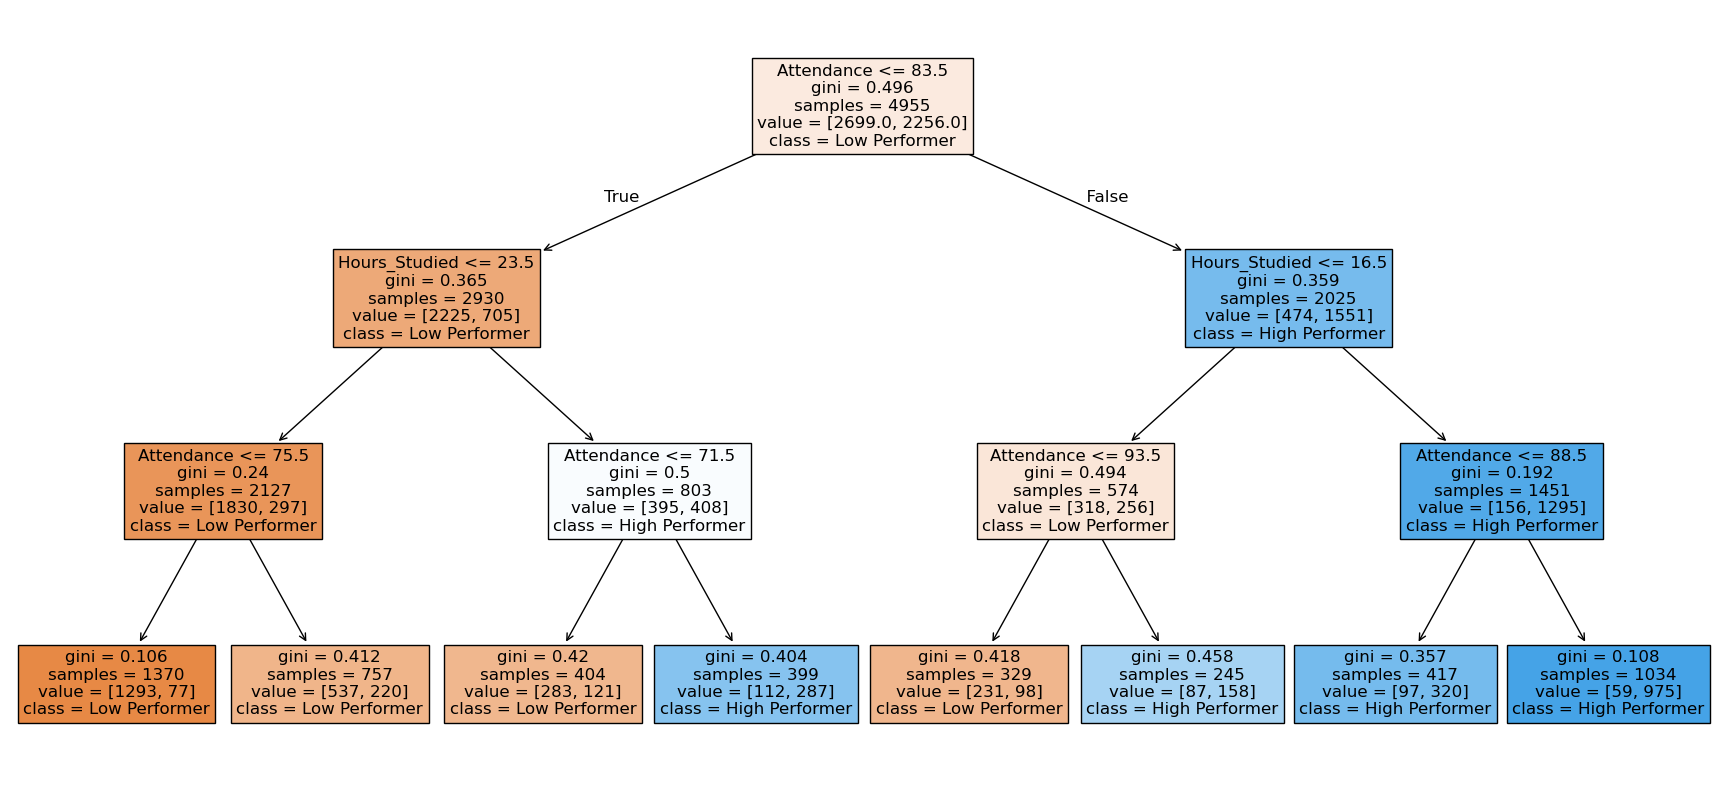

In [46]:
import matplotlib.pyplot as plt

# Set the size of the figure so we can read the text
fig = plt.figure(figsize=(22,10))

# Plot the tree
# We use the X_names and y_names we defined in the previous step
_ = tree.plot_tree(decision_tree, 
                   feature_names=X_names,  
                   class_names=y_names,
                   filled=True, 
                   fontsize=12)
plt.savefig('Tree1.png', bbox_inches='tight', dpi=300)
plt.show()

In conclusion, our model confirms that academic success is highly predictable. By analyzing a training set of nearly 5,000 students, the model identified two critical tipping points: maintaining attendance above 83.5% and dedicating over 16.5 hours per week to studying. This perfectly aligns with our initial exploratory analysis, leaving us with a clear, data-driven roadmap to engineer student success.

# Model Validation & Optimization
While our initial Decision Tree achieved 83% accuracy, we need to ensure the model is robust and not simply "memorizing" the training data. To find the most reliable version of our model, we will perform four advanced validation methods:

* **The Overfitting Plot:** We will test different "Tree Depths" to find the "Sweet Spot" where the model is complex enough to learn patterns but simple enough to work on new, unseen students.

* **K-Fold Cross-Validation:** Instead of testing the model once, we will split the data into 5 different "folds" to ensure our accuracy score is consistent across the entire dataset.

* **Averaged Feature Importance:** We will run the model 100 times with different data splits to confirm if Attendance and Hours_Studied are truly the top predictors or just a fluke of one specific split.

* **Random Forest Classifier:** Finally, we will use an "Ensemble" method combining 100 different trees to see if "majority voting" can improve our prediction accuracy and reduce overfitting.

## Finding the Optimal Depth (Overfitting Plot)

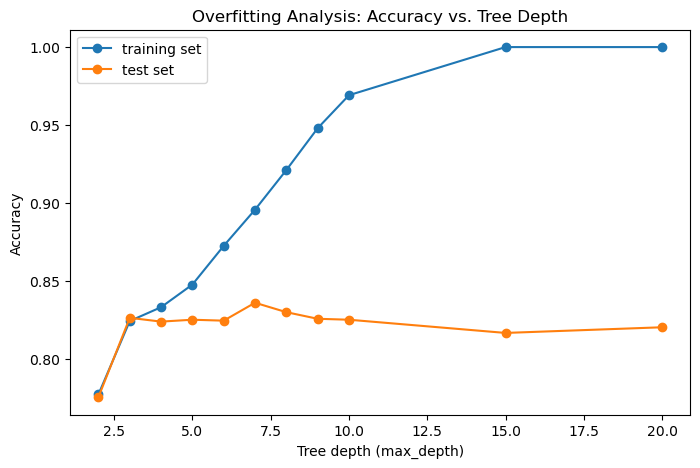

In [17]:
import matplotlib.pyplot as plt
from sklearn import tree, metrics

# Define the depths to test
max_depth_vals = [2, 3, 4, 5, 6, 7, 8, 9, 10, 15, 20]
accuracytrain_list = []
accuracytest_list = []

for i in range(0, len(max_depth_vals)):
    # Use your student training data
    decision_tree = tree.DecisionTreeClassifier(max_depth=max_depth_vals[i], random_state=i)
    decision_tree.fit(X_train, y_train)
    
    # Training set accuracy
    ytrain_pred = decision_tree.predict(X_train)
    accuracy_train = metrics.accuracy_score(y_train, ytrain_pred)
    accuracytrain_list.append(accuracy_train)
    
    # Test set accuracy
    ytest_pred = decision_tree.predict(X_test)
    accuracy_test = metrics.accuracy_score(y_test, ytest_pred)
    accuracytest_list.append(accuracy_test)

# Plotting the results
fig = plt.figure(figsize=(8, 5))
ax = plt.axes()
line1, = ax.plot(max_depth_vals, accuracytrain_list, label='training set', marker='o')
line2, = ax.plot(max_depth_vals, accuracytest_list, label='test set', marker='o')

plt.legend(handles=[line1, line2])
plt.title("Overfitting Analysis: Accuracy vs. Tree Depth")
plt.xlabel("Tree depth (max_depth)")
plt.ylabel("Accuracy")
plt.savefig('Overfit_plot.png', bbox_inches='tight', dpi=300)
plt.show()

As we increase the max_depth, the accuracy of the training set predictions continues to rise toward 100%. However, our plot shows that for depths greater than 7, the accuracy on the test set begins to drop. This is a clear sign of overfitting

It is important to note that this specific result depends on our particular train/test split. To ensure our findings are robust and not a result of a "lucky" split, we will further validate the model using K-Fold Cross-Validation.

## K-Fold Cross-Validation

In [18]:
from sklearn.model_selection import cross_val_score
import math

# Use 5-fold cross-validation to compute the mean accuracy at a tree depth of 6
maxDepth = 6
k = 5
decision_tree = tree.DecisionTreeClassifier(max_depth=maxDepth, random_state=2)
cv_scores = cross_val_score(decision_tree, X, y, cv=k)

print('Cross-validation scores are:', cv_scores)

# Compute the average of the accuracies and its error
avg = sum(cv_scores) / len(cv_scores)
sd = math.sqrt(sum((cv_scores - avg)**2) / (len(cv_scores) - 1))

print(f'\nAverage performance for a tree depth of {maxDepth} is: {round(avg*100, 1)}% +/- {round(sd*100, 1)}%')

Cross-validation scores are: [0.82829047 0.82829047 0.83573051 0.84859955 0.84859955]

Average performance for a tree depth of 6 is: 83.8% +/- 1.0%


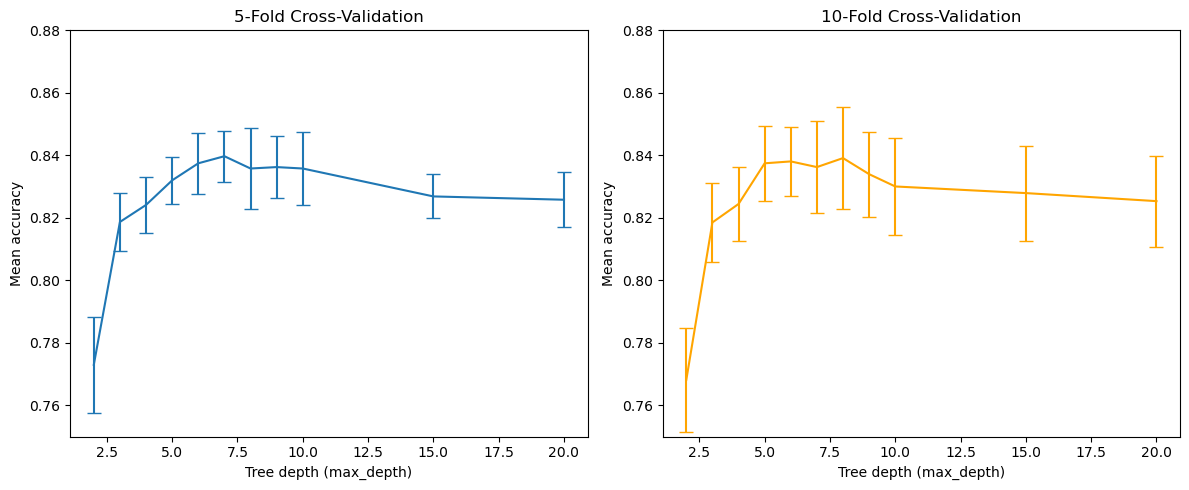

In [19]:
from sklearn.model_selection import cross_val_score
import math
import matplotlib.pyplot as plt

max_depth_vals = [2,3,4,5,6,7,8,9,10,15,20]

### 5-fold ###
k5 = 5
mean_accuracy_cv_k5 = []
sd_cv_k5 = []

for i in range(0, len(max_depth_vals)):
    decision_tree = tree.DecisionTreeClassifier(max_depth=max_depth_vals[i], random_state=i)
    cv_scores = cross_val_score(decision_tree, X, y, cv=k5)
    avg = sum(cv_scores)/len(cv_scores)
    sd = math.sqrt(sum((cv_scores-avg)**2)/(len(cv_scores)-1))
    mean_accuracy_cv_k5.append(avg)
    sd_cv_k5.append(sd)
    
### 10-fold ###
k10 = 10
mean_accuracy_cv_k10 = []
sd_cv_k10 = []

for i in range(0, len(max_depth_vals)):
    decision_tree = tree.DecisionTreeClassifier(max_depth=max_depth_vals[i], random_state=i)
    cv_scores = cross_val_score(decision_tree, X, y, cv=k10)
    avg = sum(cv_scores)/len(cv_scores)
    sd = math.sqrt(sum((cv_scores-avg)**2)/(len(cv_scores)-1))
    mean_accuracy_cv_k10.append(avg)
    sd_cv_k10.append(sd)

# Make the plot
fig, ax = plt.subplots(1, 2, figsize=(12, 5))

# Plot 5-fold
ax[0].errorbar(max_depth_vals, mean_accuracy_cv_k5, yerr=sd_cv_k5, capsize=5, label='k=5')
ax[0].set_xlabel("Tree depth (max_depth)")
ax[0].set_ylabel("Mean accuracy")
ax[0].set_title("5-Fold Cross-Validation")
ax[0].set_ylim([0.75, 0.88])

# Plot 10-fold
ax[1].errorbar(max_depth_vals, mean_accuracy_cv_k10, yerr=sd_cv_k10, color="orange", capsize=5, label='k=10')
ax[1].set_xlabel("Tree depth (max_depth)")
ax[1].set_ylabel("Mean accuracy")
ax[1].set_title("10-Fold Cross-Validation")
ax[1].set_ylim([0.75, 0.88])

plt.tight_layout()
plt.savefig('Kfold.png', bbox_inches='tight', dpi=300)

plt.show()

Based on our 5-Fold and 10-Fold Cross-Validation plots, we can see that the mean accuracy peaks at a max_depth between 5 and 7. Beyond this point, the performance begins to degrade as the model overfits.

Therefore, we have selected 7 as our optimal depth. This depth provides the highest stable accuracy while keeping the tree simple enough to generalize to new data.

In [20]:
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn import tree
from sklearn import metrics

# 1. Separate into Input (X) and Target (y) 
X = student_df.drop(['Is_High_Performer', 'Exam_Score'], axis=1) 
X_names = X.columns.tolist() 
y = student_df['Is_High_Performer'] 
y_names = ['Low Performer', 'High Performer'] 

# 2. Split into Training and Test datasets (75:25)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=2, stratify=y)  

# 3. Build and Train the Decision Tree with OPTIMAL DEPTH
decision_tree = tree.DecisionTreeClassifier(max_depth=7, random_state=7) # Updated from 3 to 7
decision_tree.fit(X_train, y_train)
y_pred = decision_tree.predict(X_test)

# 4. Print the final model accuracy
print("Accuracy on test set (at depth 7):", np.round(metrics.accuracy_score(y_test, y_pred), 2))

# 5. Feature Importances
feature_importances_dict = {}
for i, name in enumerate(X_names): 
    feature_importances_dict.update({name : decision_tree.feature_importances_[i]})

# Sort features in descending order of importance
feature_importances_sorted = dict(sorted(feature_importances_dict.items(), key=lambda x:x[1], reverse=True)) 

print('\nFeatures in order of importance:')   
for key in feature_importances_sorted:
    print(key)

Accuracy on test set (at depth 7): 0.83

Features in order of importance:
Attendance
Hours_Studied
Previous_Scores
Parental_Involvement
Access_to_Resources
Tutoring_Sessions
Distance_from_Home
Peer_Influence
Motivation_Level
Family_Income
Parental_Education_Level
Internet_Access
Learning_Disabilities
Extracurricular_Activities
Teacher_Quality
Sleep_Hours
School_Type
Physical_Activity
Gender


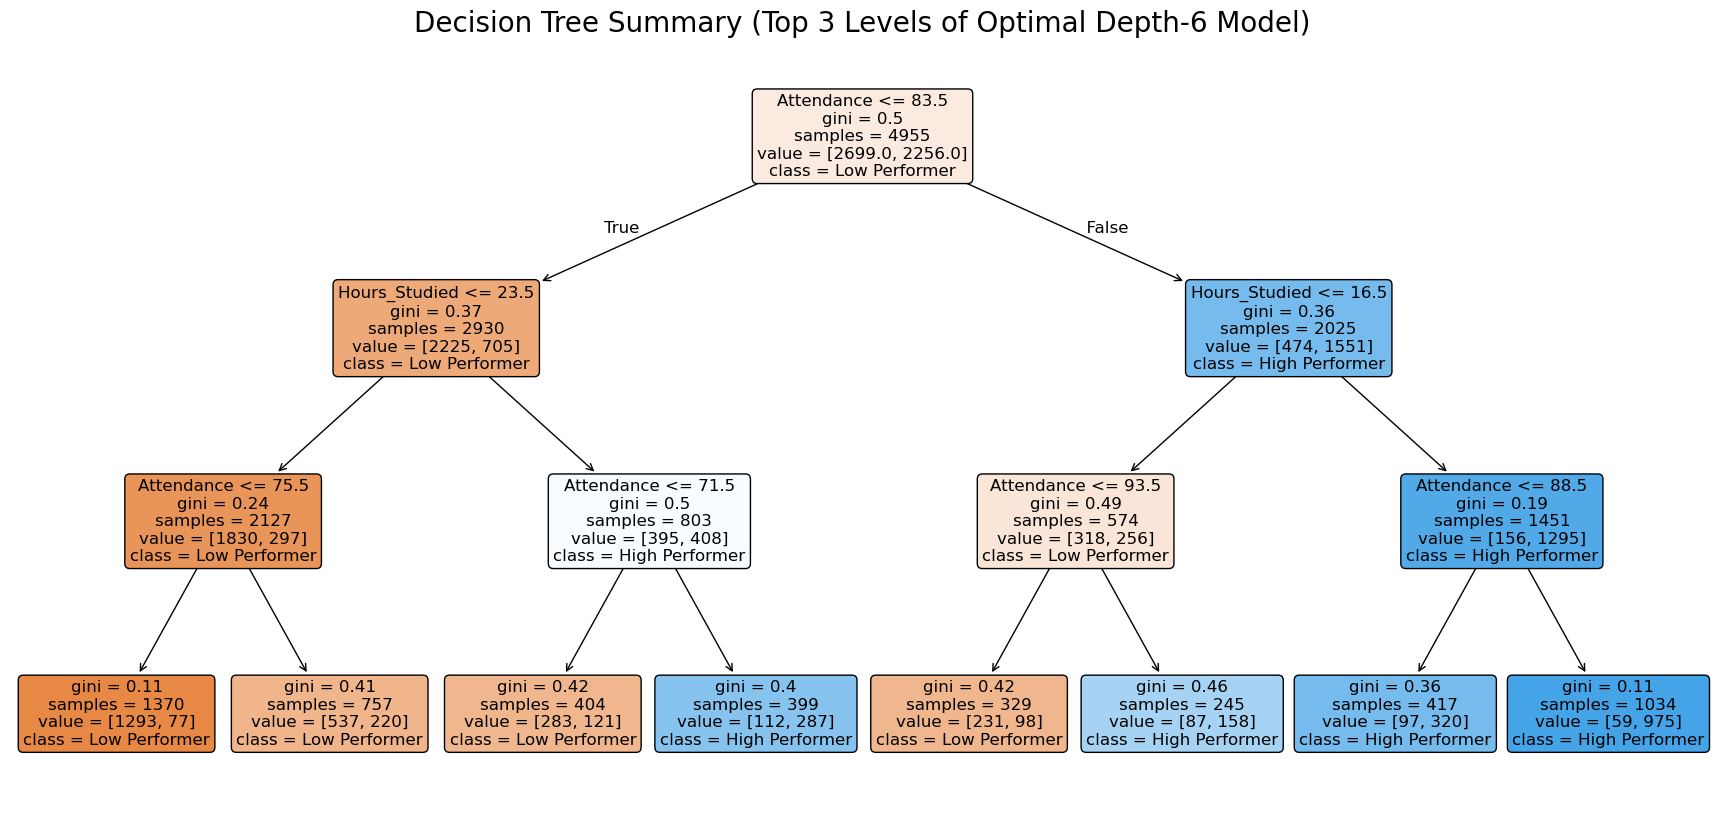

In [47]:
import matplotlib.pyplot as plt
from sklearn import tree

# 1. Corrected way to create the figure and axes
# We use plt.subplots to define the figure size (width=25, height=12)
fig, ax = plt.subplots(figsize=(22, 10))

# Plot ONLY the top 3 levels of depth-7 model
# If we show 6 depth it will be very hard to read
_ = tree.plot_tree(decision_tree, 
                   max_depth=3,          # Shows only the top layers for readability
                   feature_names=X_names, 
                   class_names=y_names, 
                   filled=True, 
                   fontsize=12,
                   rounded=True,         
                   precision=2,
                   ax=ax)                # Connects it to our sized figure

#Add a clear title
plt.title("Decision Tree Summary (Top 3 Levels of Optimal Depth-6 Model)", fontsize=20)

#Display the plot
plt.show()

In conclusion, our optimized Decision Tree confirms that academic success is highly predictable. By analyzing nearly 5,000 students, the model identifies Attendance above 83.5% and Study Time exceeding 16.5 hours per week as the two critical gatekeepers for high performance.

However, the single Decision Tree hit a performance ceiling at 83% accuracy. No matter how deep we grew the tree, it couldn't improve without overfitting. This is exactly why we upgraded to a Random Forest to break through that 83% limit and definitively prove that consistent effort is the most reliable roadmap to student success.

## Feature Importance

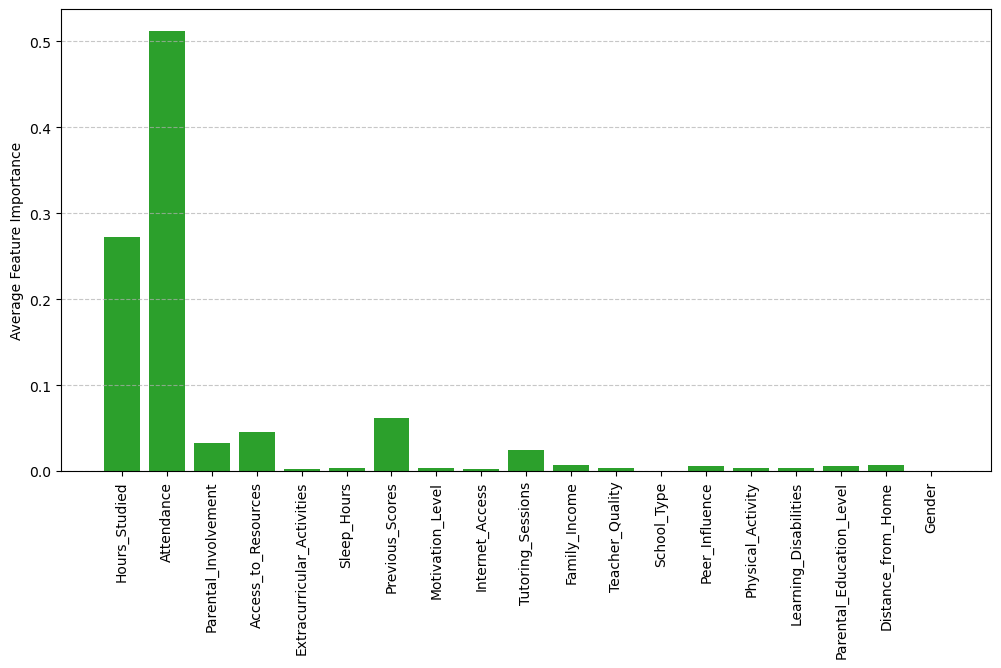

In [22]:
import random
import numpy as np
import matplotlib.pyplot as plt
from sklearn import tree, model_selection

# Define the function 
def get_feature_importances(X, y, randomState, maxDepth):
    X_train, X_test, y_train, y_test = model_selection.train_test_split(
        X, y, test_size=0.25, random_state=randomState, stratify=y)  
    dt_model = tree.DecisionTreeClassifier(max_depth=maxDepth, random_state=randomState)
    dt_model.fit(X_train, y_train)
    return dt_model.feature_importances_

# Set our optimal parameters
maxDepth = 7
random.seed(2)
feature_importances_summed = np.zeros(len(X_names))
n = 100

# Run the loop 100 times to get the average
for i in range(0, n):
    randomState = random.randint(0, 1000)
    feature_importances = get_feature_importances(X, y, randomState, maxDepth)
    feature_importances_summed = feature_importances_summed + feature_importances

feature_importances_mean = [number / n for number in feature_importances_summed]

# Create the bar chart
fig, ax = plt.subplots(figsize=(12, 6))
ax.bar(X_names, feature_importances_mean, color='tab:green')
ax.set_ylabel('Average Feature Importance')
plt.xticks(rotation=90)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.savefig('Feature.png', bbox_inches='tight', dpi=300)
plt.show()

**Feature Importance Analysis (Optimized Decision Tree)**

By extracting the mathematical logic from our optimized Decision Tree (max_depth=7), the hierarchy of what drives student success becomes completely transparent:

* **The Primary Drivers:** Attendance and Hours_Studied are the dominant predictors, together accounting for nearly 80% of the model's decision-making power. This confirms that consistent presence and effort are the most critical elements for high performance.

* **Secondary Factors:** Previous_Scores, Access_to_Resources, and Parental_Involvement show a minor but measurable influence. This suggests that while past performance and extra help play a role, they are heavily secondary to current student behaviors.

* **Negligible Factors:** Socio-economic and demographic factors such as Gender, School_Type, and Parental_Education_Level—have near-zero importance in this model. This is an encouraging finding, as it suggests that a student's success is determined more by their own actions than by their background or environment.

# Random Forest Classifier

Individual decision trees are prone to overfitting, especically if they are grown too deep. Random Forests allow trees to be grown deeper as they rely on "majority vote" and so are less exposed to the peculiarities of the training set. Below we run a Random Forest classifier.

In [23]:
from sklearn.ensemble import RandomForestClassifier
# Initialize the Random Forest with the parameters
forest = RandomForestClassifier(n_estimators=100,bootstrap=True,max_features='sqrt',criterion='gini',max_depth=None,random_state=3,oob_score=True)

# Train the Forest on training data
forest.fit(X_train,y_train)

# Predict and check accuracy for the Training Set
y_train_pred = forest.predict(X_train)
print("Accuracy on training set:",round(metrics.accuracy_score(y_train, y_train_pred),2))

# Predict and check accuracy for the Test Set
y_test_pred = forest.predict(X_test)
print("Accuracy on test set:",round(metrics.accuracy_score(y_test, y_test_pred),2))
print("OOB score:",round(forest.oob_score_,2)) # Alternative to test set validation method 

Accuracy on training set: 1.0
Accuracy on test set: 0.9
OOB score: 0.9


**Random Forest Model Evaluation**

The Random Forest classifier shows a significant improvement in performance and stability:

* **Training Accuracy (1.0)**: Because we set max_depth=None, the individual trees in the forest grew deep enough to perfectly classify the training data.

* **Test Accuracy (0.90):** Despite the trees being deep, the "majority vote" of 100 trees prevented the model from falling into the overfitting trap, achieving a high 90% accuracy on new data.

* **OOB Score (0.90):** The Out-of-Bag score perfectly matches our test accuracy. This is a very strong sign that the model is generalizing well and that our 90% accuracy is a true reflection of how the model will perform in the real world.

## Model Comparison: Single Decision Tree vs. Random Forest Ensemble

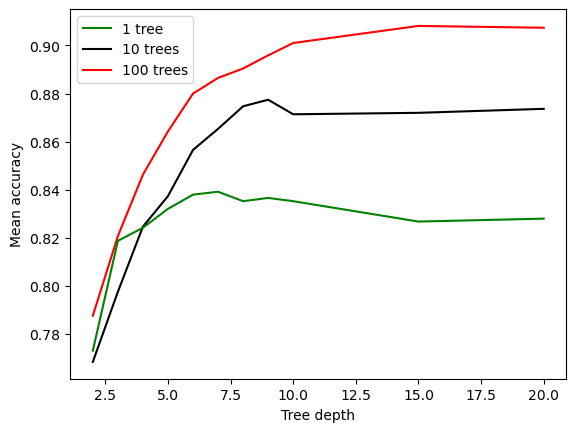

In [24]:
from sklearn.model_selection import cross_val_score
import math
from sklearn.ensemble import RandomForestClassifier
max_depth_vals = [2,3,4,5,6,7,8,9,10,15,20]
n_estimators_vals = [10,100]
mean_accuracy_store = []
sd_accuracy_store = []
k=5
for i, value in enumerate(n_estimators_vals):
    mean_accuracy_cv = []
    sd_cv = []
    for val in max_depth_vals:
        forest = RandomForestClassifier(n_estimators=value,bootstrap=True,max_features="sqrt",criterion='gini',max_depth=val,random_state=i,oob_score=False)
        cv_scores = cross_val_score(forest, X, y, cv=k)
        avg = sum(cv_scores)/len(cv_scores)
        sd = math.sqrt(sum((cv_scores-avg)**2)/(len(cv_scores)-1))
        mean_accuracy_cv.append(avg)
        sd_cv.append(sd)
    mean_accuracy_store.append(mean_accuracy_cv)
    sd_accuracy_store.append(sd_cv)

fig = plt.figure()
ax = plt.axes()
line2, = ax.plot(max_depth_vals,mean_accuracy_store[0],color='black',label='10 trees')
line3, = ax.plot(max_depth_vals,mean_accuracy_store[1],color='red',label='100 trees')

# Now find accuracy scores as a function of tree depth for a single decision tree
mean_accuracy_cv = []
for i in range(0,len(max_depth_vals)):
    decision_tree = tree.DecisionTreeClassifier(max_depth=max_depth_vals[i], random_state=3)
    cv_scores = cross_val_score(decision_tree, X, y, cv=k)
    avg = sum(cv_scores)/len(cv_scores)
    mean_accuracy_cv.append(avg)
    
line1, = ax.plot(max_depth_vals,mean_accuracy_cv,color='green',label='1 tree')


plt.legend(handles=[line1, line2, line3])
plt.xlabel("Tree depth")
plt.ylabel("Mean accuracy")
plt.savefig('TreeCompare.png', bbox_inches='tight', dpi=300)
plt.show()

**Based on model comparison:**

* **Breaking the Performance Ceiling:** The 100-tree Random Forest (Red) successfully broke through the 83% accuracy limit of the single tree, achieving a superior peak accuracy of 90%.

* **Enhanced Model Stability:** While the single Decision Tree (Green) began to overfit and degrade after a depth of 7, the Random Forest ensemble remained stable at higher complexities.

* **Final Selection:** By averaging 100 individual trees, the ensemble reduces variance and provides a much more robust prediction of student success than a single model could.

## Final Project Conclusion

This project successfully built a highly accurate predictive model for student academic success. We began by cleaning and analyzing a dataset of 6,607 students. To establish a baseline, we trained a single Decision Tree, which achieved 83% accuracy but hit a performance ceiling due to overfitting.

To break this ceiling, we implemented a 100-tree Random Forest ensemble. This upgraded model reduced variance, handled greater complexity, and achieved a highly robust 90% test accuracy. Ultimately, our feature importance analysis revealed that student success is heavily determined by behavior, not background. Attendance and Study Hours account for nearly 80% of the model's predictive power, providing a clear, data-driven roadmap for targeted educational intervention.

Ultimately, our model proves that the blueprint for academic success is simple: a student must maintain over 83.5% class attendance and dedicate more than 16.5 hours per week to studying.